# 04 — NIG Process Simulation

This notebook simulates trajectories of the NIG process. First, trajectories using the estimated parameter values from the calibration are simulated. Then, trajectories using different sets of parameter values are simulated to understand the effect of each parameter on the process. 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Simulation of NIG process trajectories 

The NIG process depends on three parameters: $\alpha > 0$, $\beta \in (-\alpha, \alpha)$, $\delta > 0$. 

Following Schoutens (2003) each trajectory is simulated through a time-changed Brownian motion and an IG process with parameters $a = 1$ and $b = \delta\sqrt{\alpha^2 - \beta^2}$. 


In [3]:
# Load the calibrated parameters  

from pathlib import Path
import sys
import pickle

cwd = Path.cwd()
PROJECT_ROOT = next(
    (
        folder for folder in (cwd, *cwd.parents)
        if (folder / "src" / "calibration.py").is_file()
    ),
    None,
)


RESULT_PATH = PROJECT_ROOT / "results" / "calibration_result.pkl"

sys.path.insert(0, str(PROJECT_ROOT))

with RESULT_PATH.open("rb") as file:
    calibration_result = pickle.load(file)

print(calibration_result)

CalibrationResult(parameters=NIGParameters(alpha=13.527722472498198, beta=-9.525035530742965, delta=0.20862148989303406, mu=0.0), mean_squared_error=98.34431035802956, root_mean_squared_error=9.916869987956359, success=True, message='`ftol` termination condition is satisfied.', function_evaluations=12, number_of_quotes=477)


In [4]:
# Set-up for the time horizon and the number of time steps for the simulation
T = 1       # Time horizon 
N = 1000    # Number of time steps
dt = T/N    # Time step size
t = np.linspace(0, T, N+1)  # Time grid

In [5]:
# Simulation of an IG process (I_t ~ IG(at, b)) with a = 1 and b = delta* sqrt(alpha^2 - beta^2)

def simulate_ig_increments(alpha, beta, delta, dt, N):
    a = 1 
    b = delta * np.sqrt(alpha**2 - beta**2)

    # Start by simulating IG random numbers (IG(a * dt, b)) with a = 1 and b = delta* sqrt(alpha^2 - beta^2)
    v= np.random.standard_normal(size=N)
    y = v**2
    x = (a*dt/b) + y / (2*b**2) - np.sqrt(4*a*dt*b*y + y**2) / (2*b**2)
    u = np.random.uniform(size = N)

    # This is a vector containing all increments of the IG process (size = N). 
    ig_increments = np.where(u <= (a*dt) / (a*dt + b*x), x, (a*dt)**2 / (b**2 * x)) # return x if u <= (a*dt) / (a*dt + b*x) else (a*dt)^2 / (b^2 * x)

    return ig_increments

# Simulation of an NIG process 
def simulate_nig_process(alpha, beta, delta, dt):

    # Simulate the IG process
    ig_increments = simulate_ig_increments(alpha, beta, delta, dt, N)

    # Simulate the NIG process as a time-changed Brownian motion
    nig_increments = beta * delta**2 * ig_increments + delta * np.sqrt(ig_increments) * np.random.standard_normal(size=N)

    # Compute the cumulative sum to get the NIG process
    nig_process = np.concatenate(([0.0], np.cumsum(nig_increments)))

    return nig_process



In [6]:
# Make the simulation reproducible by setting a random seed
rng = np.random.default_rng(12) 

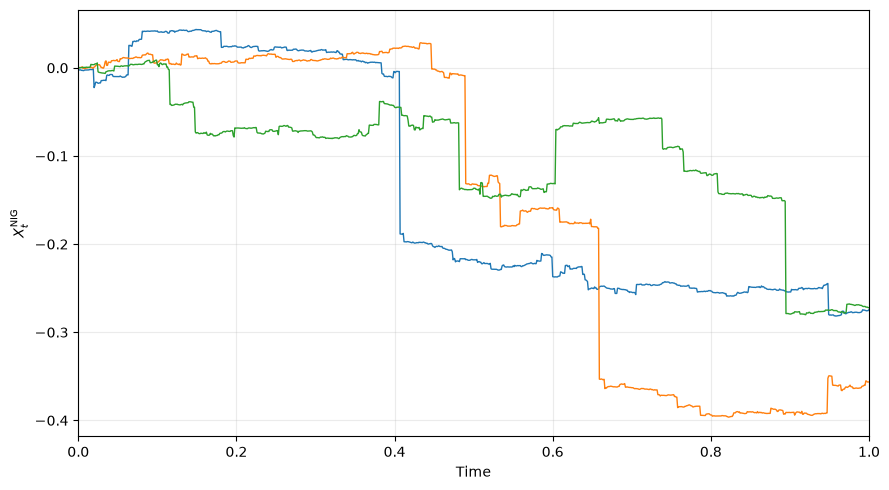

In [ ]:
alpha_rounded = round(calibration_result.parameters.alpha, 5)
beta_rounded = round(calibration_result.parameters.beta, 5)
delta_rounded = round(calibration_result.parameters.delta, 5)

nig_proces_calib_1 = simulate_nig_process(
    alpha=alpha_rounded,
    beta=beta_rounded,
    delta=delta_rounded,
    dt=dt
)

nig_proces_calib_2 = simulate_nig_process(
    alpha=alpha_rounded,
    beta=beta_rounded,
    delta=delta_rounded,
    dt=dt
)
nig_proces_calib_3 = simulate_nig_process(
    alpha=alpha_rounded,
    beta=beta_rounded,
    delta=delta_rounded,
    dt=dt
)

plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_calib_1, linewidth=1.0)
plt.plot(t, nig_proces_calib_2, linewidth=1.0)
plt.plot(t, nig_proces_calib_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

## 2. Parameter Effects on the NIG Process

### Effect of $\alpha$

In [ ]:
alpha = 0.1
beta = 0 
delta = 0.1622

In [9]:
nig_proces_alpha1_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_alpha1_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_alpha1_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)

In [10]:
alpha = 20
beta = 0 
delta = 0.1622

In [11]:
nig_proces_alpha2_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_alpha2_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_alpha2_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)


In [12]:
all_paths = [
    nig_proces_alpha1_1, nig_proces_alpha1_2, nig_proces_alpha1_3,
    nig_proces_alpha2_1, nig_proces_alpha2_2, nig_proces_alpha2_3,
]

y_min = min(path.min() for path in all_paths)
y_max = max(path.max() for path in all_paths)

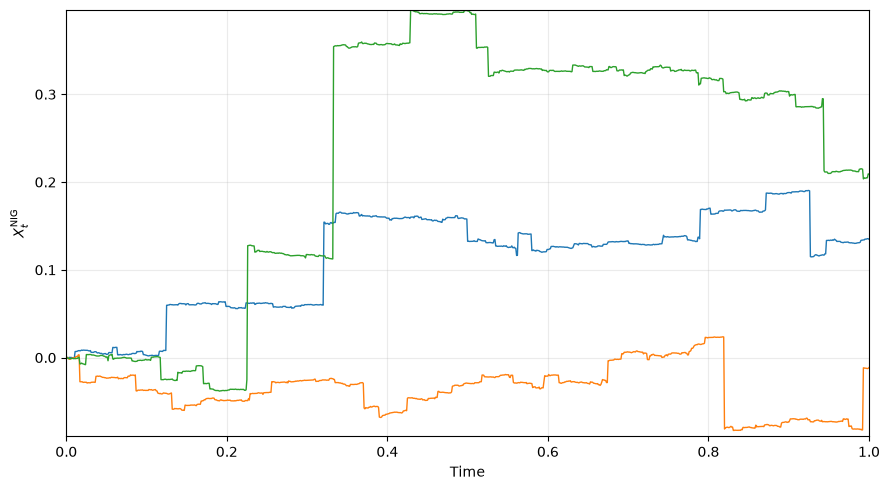

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_alpha1_1, linewidth=1.0)
plt.plot(t, nig_proces_alpha1_2, linewidth=1.0)
plt.plot(t, nig_proces_alpha1_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_alpha1.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

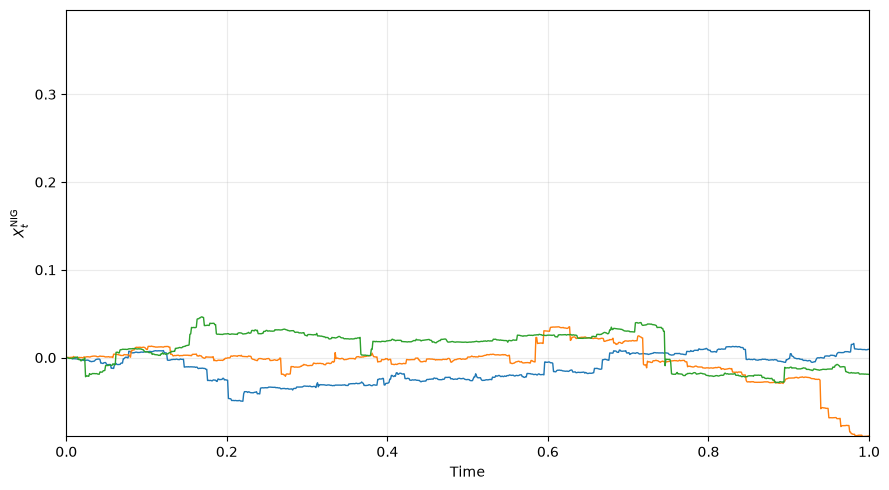

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_alpha2_1, linewidth=1.0)
plt.plot(t, nig_proces_alpha2_2, linewidth=1.0)
plt.plot(t, nig_proces_alpha2_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_alpha2.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

### Effect of $\beta$

In [35]:
alpha =  6.1882
beta = 1 
delta = 0.1622

In [36]:
nig_proces_beta1_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_beta1_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_beta1_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)

In [47]:
alpha =  6.1882
beta = -6
delta = 0.1622

In [48]:
nig_proces_beta2_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_beta2_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_beta2_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)

In [49]:
all_paths = [
    nig_proces_beta1_1, nig_proces_beta1_2, nig_proces_beta1_3,
    nig_proces_beta2_1, nig_proces_beta2_2, nig_proces_beta2_3,
]

y_min = min(path.min() for path in all_paths)
y_max = max(path.max() for path in all_paths)

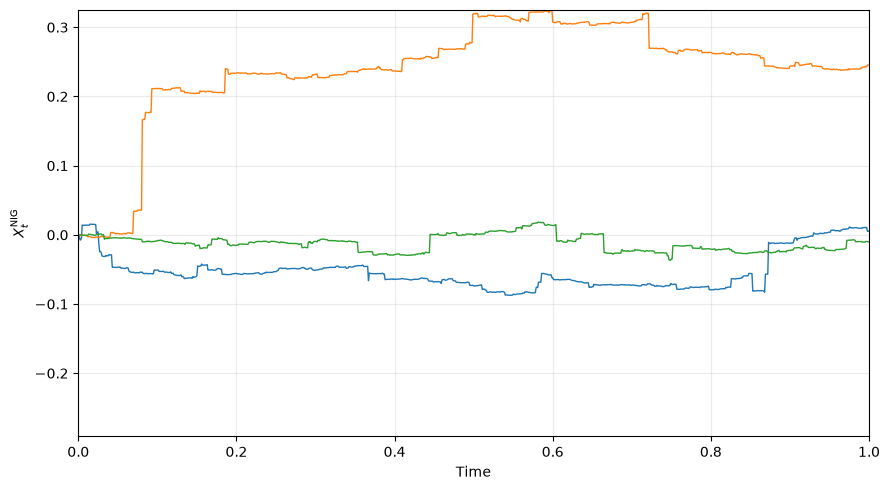

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_beta1_1, linewidth=1.0)
plt.plot(t, nig_proces_beta1_2, linewidth=1.0)
plt.plot(t, nig_proces_beta1_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_beta1.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

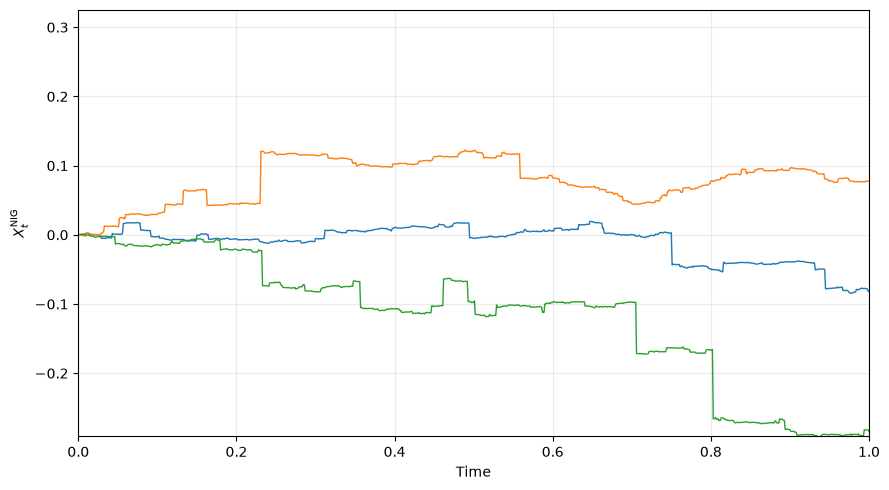

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_beta2_1, linewidth=1.0)
plt.plot(t, nig_proces_beta2_2, linewidth=1.0)
plt.plot(t, nig_proces_beta2_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_beta2.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

### Effect of $\delta$

In [59]:
alpha =  6.1882
beta = -3.8941
delta = 0.1

In [60]:
nig_proces_delta1_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_delta1_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_delta1_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)

In [66]:
alpha =  6.1882
beta = -3.8941
delta = 2

In [67]:
nig_proces_delta2_1 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt,
)
nig_proces_delta2_2 = simulate_nig_process(
    alpha=alpha,
        beta=beta,
        delta=delta,
        dt=dt,
)
nig_proces_delta2_3 = simulate_nig_process(
    alpha=alpha,
    beta=beta,
    delta=delta,
    dt=dt
)

In [68]:
all_paths = [
    nig_proces_delta1_1, nig_proces_delta1_2, nig_proces_delta1_3,
    nig_proces_delta2_1, nig_proces_delta2_2, nig_proces_delta2_3,
]

y_min = min(path.min() for path in all_paths)
y_max = max(path.max() for path in all_paths)

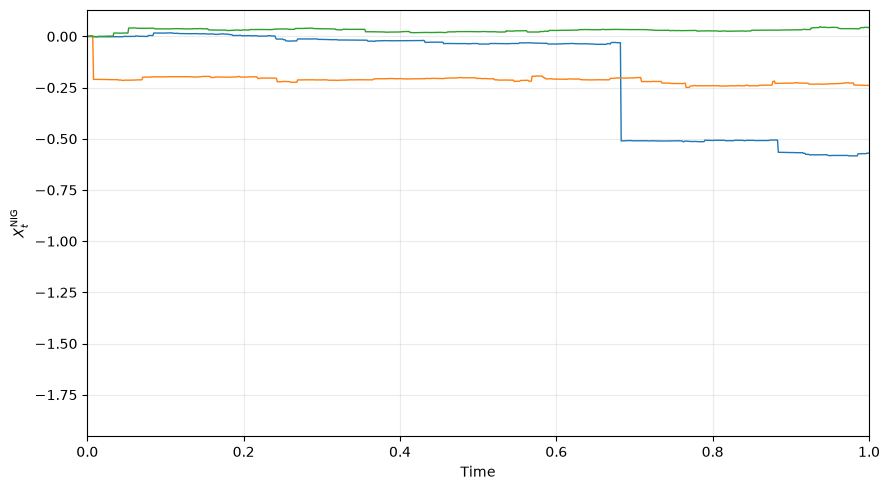

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_delta1_1, linewidth=1.0)
plt.plot(t, nig_proces_delta1_2, linewidth=1.0)
plt.plot(t, nig_proces_delta1_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_delta1.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()

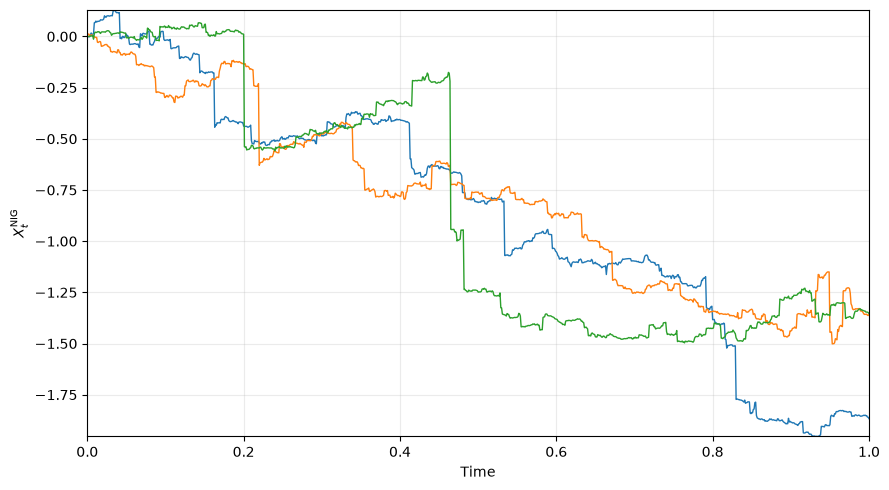

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(t, nig_proces_delta2_1, linewidth=1.0)
plt.plot(t, nig_proces_delta2_2, linewidth=1.0)
plt.plot(t, nig_proces_delta2_3, linewidth=1.0)
plt.xlim(t[0], t[-1])
plt.ylim(y_min, y_max)
plt.xlabel("Time")
plt.ylabel(r"$X_t^{\mathrm{(NIG)}}$")
plt.grid(True, alpha=0.25)
plt.tight_layout()
output_path = PROJECT_ROOT / "results" / "nig_simulated_paths_delta2.png"
plt.savefig(output_path, dpi=180, bbox_inches="tight")
plt.show()